# Fase 9 — Análisis cualitativo de fallos característicos del SAR (entregable 5)

**Enunciado:** identificar y explicar **al menos tres** tipos de error (p. ej. sombra de radar, doble rebote en zonas urbanas inundadas, confusión suelo húmedo / agua abierta) **con ejemplos visuales concretos**.

Analizamos **5 tipos**, cada uno con una figura y una **evidencia física independiente** (no solo "se ve en la imagen"):

| # | Tipo de error | Chip | Evidencia |
|---|---|---|---|
| 1 | Sombra de radar / incidencia rasante → **FP** | Lima_0104 | Ángulo de incidencia **local** (SRTM + geometría de S1): ¿los FP se concentran en laderas de espaldas al sensor? |
| 2 | Doble rebote y suelo saturado en zona urbana → **FN** | Lima_0506 | Diferencia S1 **17/03 − 05/03**: la zona inundada se **aclaró** en vez de oscurecerse |
| 3 | Vegetación inundada / agua somera no especular → **FN** | Pakistan_849790, Bolivia_314919 | Sentinel-2 del mismo evento: agua visible en óptico pero no oscura en SAR |
| 4 | Superficies secas y lisas en zonas áridas → **FP** | el chip de Somalia/Pakistán con más FP | Sentinel-2: suelo desnudo / arena, oscuro en SAR como el agua |
| 5 | Agua permanente vs. inundación (convención de etiqueta) → **FP aparente** | Lima_0506 | **JRC Global Surface Water**: ¿el FP es agua permanente? |

Modelo: el final (`solo_dorados`, pérdida combinada), semilla 42, umbral 0.5. **No necesita GPU.** Earth Engine con la **cuenta de la UNI**.

## 0. Preparación

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
from pathlib import Path
RAIZ_PROYECTO = Path('/content/drive/MyDrive/rnap_p2_inundaciones')
sys.path.insert(0, str(RAIZ_PROYECTO))

!pip install -q rasterio scikit-image geopandas pyogrio earthengine-api

Mounted at /content/drive


## 1. Módulos nuevos

In [2]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/analisis_fallos.py
"""
analisis_fallos.py
Fase 9 (entregable 5): evidencias físicas para explicar los errores característicos del SAR.

Todas las capas auxiliares se descargan con Earth Engine en la MISMA grilla del chip (misma transformación
afín que el GeoTIFF de Sentinel-1), así se superponen píxel a píxel con la predicción:
  - SRTM (pendiente y orientación) + ángulo de incidencia de S1 -> ángulo de incidencia LOCAL
  - Sentinel-2 (compuesto sin nubes) -> contexto óptico en color real
  - JRC Global Surface Water (ocurrencia) -> agua permanente
  - Sentinel-1 de otra fecha -> diferencia temporal (detección de cambio)
"""
import subprocess

import numpy as np
import rasterio

from .configuracion import BUCKET, DIR_S2_MANO

SIN_DATO = -9999.0
# Pasada descendente de Sentinel-1: el satélite viaja hacia el SSO y mira a su derecha (hacia el ONO).
# Azimut aproximado desde el terreno HACIA el sensor (~ESE). Supuesto documentado: ±5°.
AZIMUT_HACIA_SENSOR_DESCENDENTE = 103.0


# ----------------------------------------------------------------------------- utilidades de grilla
def transformacion_de(ruta_tif):
    with rasterio.open(ruta_tif) as fuente:
        return fuente.transform


def descargar_ee(ee, imagen, bandas, transformacion, tamano=512) -> dict:
    """Bandas de una ee.Image en la grilla exacta del chip -> {banda: array float32 con NaN donde no hay dato}."""
    pedido = {
        "expression": imagen.select(bandas).toFloat().unmask(SIN_DATO),
        "fileFormat": "NUMPY_NDARRAY",
        "grid": {"dimensions": {"width": tamano, "height": tamano},
                 "affineTransform": {"scaleX": transformacion.a, "shearX": 0, "translateX": transformacion.c,
                                     "shearY": 0, "scaleY": transformacion.e, "translateY": transformacion.f},
                 "crsCode": "EPSG:4326"},
    }
    datos = ee.data.computePixels(pedido)
    salida = {}
    for banda in bandas:
        arreglo = np.asarray(datos[banda], dtype=np.float32)
        arreglo[arreglo <= SIN_DATO + 1] = np.nan
        salida[banda] = arreglo
    return salida


def _region(ee, transformacion, tamano=512):
    x0, y1 = transformacion.c, transformacion.f
    x1, y0 = x0 + transformacion.a * tamano, y1 + transformacion.e * tamano
    return ee.Geometry.Rectangle([x0, y0, x1, y1])


# ----------------------------------------------------------------------------- relieve y geometría radar
def angulo_incidencia_local(pendiente, orientacion, incidencia, azimut_sensor=AZIMUT_HACIA_SENSOR_DESCENDENTE):
    """θ_local = acos( cos s·cos θ + sin s·sin θ·cos(a − φ_sensor) )  [grados]
    s = pendiente, a = orientación de la ladera, θ = incidencia elipsoidal, φ_sensor = azimut terreno→sensor.
    Ladera mirando al sensor -> θ_local ≈ θ − s (brillante). De espaldas -> θ_local ≈ θ + s (oscura; > 90° = sombra)."""
    s, a, t = np.radians(pendiente), np.radians(orientacion), np.radians(incidencia)
    coseno = np.cos(s) * np.cos(t) + np.sin(s) * np.sin(t) * np.cos(a - np.radians(azimut_sensor))
    return np.degrees(np.arccos(np.clip(coseno, -1, 1)))


def relieve_y_geometria(ee, id_escena_s1, transformacion) -> dict:
    dem = ee.Image("USGS/SRTMGL1_003")
    imagen = (ee.Image.cat([ee.Terrain.slope(dem).rename("pendiente"), ee.Terrain.aspect(dem).rename("orientacion"),
                            ee.Image(f"COPERNICUS/S1_GRD/{id_escena_s1}").select("angle").rename("incidencia")]))
    capas = descargar_ee(ee, imagen, ["pendiente", "orientacion", "incidencia"], transformacion)
    capas["incidencia_local"] = angulo_incidencia_local(capas["pendiente"], capas["orientacion"], capas["incidencia"])
    return capas


# ----------------------------------------------------------------------------- óptico y agua permanente
def estirar(rgb, p_bajo=2, p_alto=98):
    """Estiramiento por percentiles de cada banda -> [0, 1] (solo para visualizar)."""
    salida = np.zeros_like(rgb, dtype=np.float32)
    for i in range(rgb.shape[-1]):
        banda = rgb[..., i]
        validos = banda[np.isfinite(banda)]
        if validos.size == 0:
            continue
        bajo, alto = np.percentile(validos, [p_bajo, p_alto])
        salida[..., i] = np.clip((banda - bajo) / max(alto - bajo, 1e-6), 0, 1)
    return np.nan_to_num(salida)


def s2_compuesto_rgb(ee, transformacion, inicio="2017-04-01", fin="2017-12-31", nubes_max=20):
    """Mediana de Sentinel-2 (L1C) sin nubes en el periodo -> (H, W, 3) en color real, estirado."""
    coleccion = (ee.ImageCollection("COPERNICUS/S2_HARMONIZED").filterBounds(_region(ee, transformacion))
                 .filterDate(inicio, fin).filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", nubes_max)))
    capas = descargar_ee(ee, coleccion.median(), ["B4", "B3", "B2"], transformacion)
    return estirar(np.stack([capas["B4"], capas["B3"], capas["B2"]], axis=-1))


def jrc_ocurrencia(ee, transformacion):
    """% del tiempo (1984–2021) en que el píxel tuvo agua según JRC Global Surface Water. 0 = nunca."""
    for version in ["JRC/GSW1_4/GlobalSurfaceWater", "JRC/GSW1_3/GlobalSurfaceWater"]:
        try:
            capa = descargar_ee(ee, ee.Image(version).select("occurrence"), ["occurrence"], transformacion)["occurrence"]
            return np.nan_to_num(capa, nan=0.0)
        except Exception:
            continue
    raise RuntimeError("No se pudo leer JRC Global Surface Water")


def s1_en_fecha(ee, id_escena_s1, transformacion):
    capas = descargar_ee(ee, ee.Image(f"COPERNICUS/S1_GRD/{id_escena_s1}"), ["VV", "VH"], transformacion)
    return np.stack([capas["VV"], capas["VH"]])


# ----------------------------------------------------------------------------- Sentinel-2 de Sen1Floods11
def descargar_s2_sen1floods11(ids_chips):
    """Baja SOLO los chips pedidos de S2Hand (cada uno ~7 MB), no los 446."""
    DIR_S2_MANO.mkdir(parents=True, exist_ok=True)
    for id_chip in ids_chips:
        destino = DIR_S2_MANO / f"{id_chip}_S2Hand.tif"
        if not destino.exists():
            subprocess.run(["gsutil", "-q", "cp",
                            f"{BUCKET}/data/flood_events/HandLabeled/S2Hand/{id_chip}_S2Hand.tif", str(destino)],
                           check=True)


def leer_s2_rgb(id_chip):
    """S2Hand trae 13 bandas (B1..B12 con B8A); color real = B4, B3, B2 -> índices 3, 2, 1."""
    with rasterio.open(DIR_S2_MANO / f"{id_chip}_S2Hand.tif") as fuente:
        bandas = fuente.read([4, 3, 2]).astype(np.float32)
    bandas[bandas <= 0] = np.nan
    return estirar(np.moveaxis(bandas, 0, -1))


# ----------------------------------------------------------------------------- cuantificación
def enriquecimiento(mascara_error, condicion, validos) -> dict:
    """¿Los errores se concentran donde se cumple la condición más de lo esperable por azar?
    razón > 1 -> la condición está sobrerrepresentada entre los errores."""
    errores = mascara_error & validos
    pct_errores = 100 * (errores & condicion).sum() / max(errores.sum(), 1)
    pct_base = 100 * (validos & condicion).sum() / max(validos.sum(), 1)
    return {"px_error": int(errores.sum()), "%_errores_con_condicion": round(float(pct_errores), 1),
            "%_area_con_condicion": round(float(pct_base), 1),
            "razon_enriquecimiento": round(float(pct_errores / max(pct_base, 1e-6)), 2)}


Writing /content/drive/MyDrive/rnap_p2_inundaciones/src/analisis_fallos.py


In [3]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/visualizacion_fallos.py
"""
visualizacion_fallos.py
Una figura por tipo de error: fila de paneles heterogéneos (SAR, óptico, probabilidad, errores, capas físicas).
"""
import matplotlib.pyplot as plt
import numpy as np

from .visualizacion import MAPA_ETIQUETA, NORMA_ETIQUETA
from .visualizacion_final import MAPA_ERRORES, LEYENDA


def _dibujar(eje, tipo, datos, opciones):
    if tipo == "sar":
        eje.imshow(np.nan_to_num(datos, nan=opciones.get("vmin", -25)), cmap="gray",
                   vmin=opciones.get("vmin", -25), vmax=opciones.get("vmax", 0))
    elif tipo == "rgb":
        eje.imshow(datos)
    elif tipo == "prob":
        eje.imshow(datos, cmap="Blues", vmin=0, vmax=1)
    elif tipo == "errores":
        eje.imshow(datos, cmap=MAPA_ERRORES, vmin=0, vmax=4, interpolation="nearest")
    elif tipo == "etiqueta":
        eje.imshow(datos, cmap=MAPA_ETIQUETA, norm=NORMA_ETIQUETA, interpolation="nearest")
    elif tipo in ("divergente", "continuo"):
        mapa = "RdBu_r" if tipo == "divergente" else opciones.get("cmap", "viridis")
        imagen = eje.imshow(datos, cmap=mapa, vmin=opciones.get("vmin"), vmax=opciones.get("vmax"))
        plt.colorbar(imagen, ax=eje, fraction=0.046, pad=0.02).ax.tick_params(labelsize=7)
    if "contorno" in opciones:                      # p. ej. borde de la etiqueta de agua
        eje.contour(opciones["contorno"], levels=[0.5], colors=opciones.get("color_contorno", "yellow"), linewidths=0.8)


def figura_caso(titulo, paneles, ruta_guardado=None, leyenda_errores=True):
    """paneles: [(tipo, datos, subtítulo, {opciones}), ...]"""
    figura, ejes = plt.subplots(1, len(paneles), figsize=(3.4 * len(paneles), 3.9))
    for eje, (tipo, datos, subtitulo, opciones) in zip(np.atleast_1d(ejes), paneles):
        _dibujar(eje, tipo, datos, opciones)
        eje.set_title(subtitulo, fontsize=9)
        eje.axis("off")
    figura.suptitle(titulo, fontsize=11, fontweight="bold")
    if leyenda_errores:
        figura.legend(handles=LEYENDA, loc="lower center", ncol=4, frameon=False, fontsize=8)
    figura.tight_layout(rect=(0, 0.06 if leyenda_errores else 0, 1, 0.95))
    if ruta_guardado:
        figura.savefig(ruta_guardado, dpi=150, bbox_inches="tight")
    return figura


Writing /content/drive/MyDrive/rnap_p2_inundaciones/src/visualizacion_fallos.py


## 2. Earth Engine, datos y modelo final

In [4]:
import ee
try:
    ee.Initialize(project='rnap-inundaciones')
except Exception:
    ee.Authenticate()
    ee.Initialize(project='rnap-inundaciones')

import numpy as np
import pandas as pd
import torch
from scipy.ndimage import uniform_filter

from src.configuracion import *
from src.utilidades import fijar_semilla, obtener_dispositivo
from src.descarga import descargar_mano
from src.preprocesamiento import Normalizador
from src.lectura import leer_particion, leer_s1
from src.conjunto_datos import ConjuntoInundaciones
from src.entrenamiento import cargar_mejor_modelo
from src.evaluacion import predecir_probabilidades
from src.evaluacion_final import CARPETAS, elegir_variante
from src.evaluacion_lima import ConjuntoLima, ids_lima, DIR_S1_LIMA
from src.visualizacion_final import mapa_errores
from src.analisis_fallos import (transformacion_de, relieve_y_geometria, s1_en_fecha, s2_compuesto_rgb, jrc_ocurrencia,
                                 descargar_s2_sen1floods11, leer_s2_rgb, enriquecimiento)
from src.visualizacion_fallos import figura_caso

dispositivo = obtener_dispositivo()
fijar_semilla(SEMILLA)
descargar_mano()
normalizador = Normalizador.desde_json(DIR_RESULTADOS / 'f1_estadisticas_normalizacion.json')
variante_final, _ = elegir_variante(DIR_RESULTADOS / 'f6a_ablacion_corridas.csv')
modelo, _, _ = cargar_mejor_modelo(DIR_RESULTADOS / 'experimentos' / f'{CARPETAS[variante_final]}_s42', dispositivo)

escenas = pd.read_csv(DIR_RESULTADOS / 'f8_escenas_s1_lima.csv')
es_vh = escenas['polarizaciones'].str.contains('VH') & (escenas['orbita_relativa'] == 171)
ID_1703 = escenas[es_vh & escenas['fecha_hora'].str.startswith('2017-03-17')].iloc[0]['id']
ID_0503 = escenas[es_vh & escenas['fecha_hora'].str.startswith('2017-03-05')].iloc[0]['id']

conjunto_lima = ConjuntoLima(ids_lima(), normalizador, en_memoria=False)

def analizar(conjunto, id_chip):
    """Predicción del modelo final + máscaras de error para un chip."""
    imagen, etiqueta, _ = conjunto[conjunto.ids_chips.index(id_chip)]
    prob = predecir_probabilidades(modelo, imagen, dispositivo).numpy()
    et = etiqueta.numpy()
    validos = et != VALOR_SIN_DATO
    return {'s1': leer_s1(id_chip, conjunto.dir_s1, conjunto.sufijo_s1), 'etiqueta': et, 'prob': prob,
            'errores': mapa_errores(et, prob), 'validos': validos,
            'fp': (prob > 0.5) & (et == 0), 'fn': (prob <= 0.5) & (et == 1), 'vp': (prob > 0.5) & (et == 1)}

resumen_casos = []

OJO: sin GPU. En Colab: Entorno de ejecución > Cambiar tipo > T4 GPU
[descargando] S1Hand ...
[descargando] LabelHand ...
[descargando] S1OtsuLabelHand ...
[descargando] flood_handlabeled ...


## Caso 1 — Sombra de radar / incidencia rasante (FP) · Lima_0104
**Física:** el S1 descendente mira hacia el **ONO**. Las laderas orientadas **de espaldas al sensor** reciben el pulso de forma rasante (ángulo de incidencia local grande) o no lo reciben (sombra, θ_local > 90°) → retrodispersión muy baja → **parecen agua** (oscuras y lisas).
**Prueba:** ¿los falsos positivos se concentran en píxeles con θ_local > 60°, más de lo que ocupan en el chip? (razón de enriquecimiento > 1).

θ incidencia elipsoidal media: 44.9°
θ_local mediano — en FP: 66.9° | en todo el chip: 47.2°
{'px_error': 23168, '%_errores_con_condicion': 76.5, '%_area_con_condicion': 23.0, 'razon_enriquecimiento': 3.33}


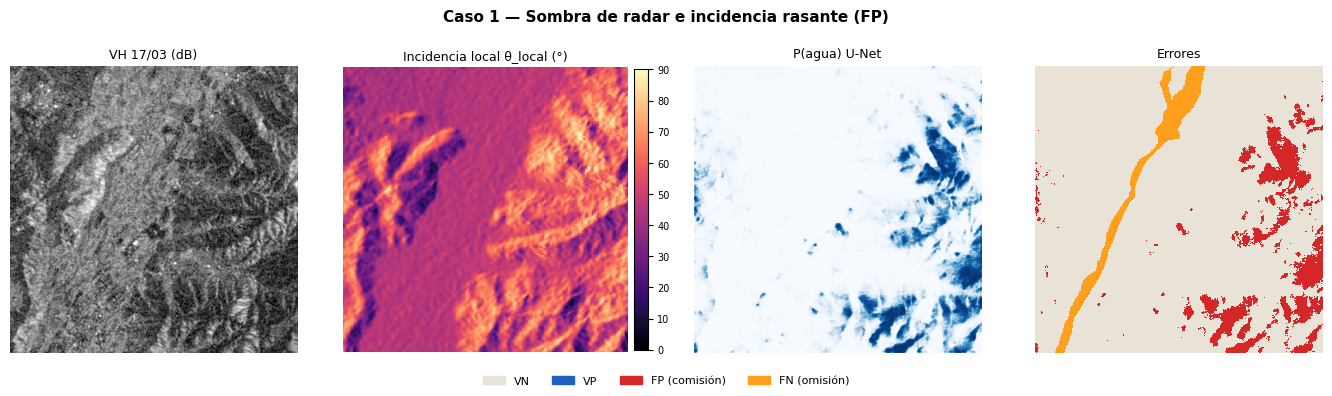

In [5]:
ID = 'Lima_0104'
d = analizar(conjunto_lima, ID)
T = transformacion_de(DIR_S1_LIMA / f'{ID}_S1Hand.tif')
geo = relieve_y_geometria(ee, ID_1703, T)
rasante = geo['incidencia_local'] > 60
e = enriquecimiento(d['fp'], rasante, d['validos'])
print(f"θ incidencia elipsoidal media: {np.nanmean(geo['incidencia']):.1f}°")
print(f"θ_local mediano — en FP: {np.nanmedian(geo['incidencia_local'][d['fp']]):.1f}° | en todo el chip: {np.nanmedian(geo['incidencia_local'][d['validos']]):.1f}°")
print(e)
resumen_casos.append({'caso': '1. Sombra / incidencia rasante', 'chip': ID, 'error': 'FP',
                      'evidencia': f"{e['%_errores_con_condicion']}% de los FP con θ_local>60° vs {e['%_area_con_condicion']}% del área (×{e['razon_enriquecimiento']})"})
figura_caso('Caso 1 — Sombra de radar e incidencia rasante (FP)', [
    ('sar', d['s1'][1], 'VH 17/03 (dB)', {'vmin': -30, 'vmax': -5}),
    ('continuo', geo['incidencia_local'], 'Incidencia local θ_local (°)', {'vmin': 0, 'vmax': 90, 'cmap': 'magma'}),
    ('prob', d['prob'], 'P(agua) U-Net', {}),
    ('errores', d['errores'], 'Errores', {}),
], DIR_FIGURAS / 'f9_caso1_sombra.png');

## Caso 2 — Doble rebote y suelo saturado en zona urbana inundada (FN) · Lima_0506 (Carapongo)
**Física:** en calles inundadas el pulso rebota agua → pared → sensor (**doble rebote**, sobre todo en VV) y el barro saturado tiene alta constante dieléctrica: ambos **aumentan** la retrodispersión. El agua especular de entrenamiento, en cambio, la **disminuye**.
**Prueba:** diferencia VV 17/03 − 05/03 (misma órbita 171; suavizado 5×5 contra el speckle) dentro y fuera de la etiqueta.

ΔVV mediana — inundado: +1.22 dB | no inundado: +0.03 dB
FN: 45,484 de 45,495 píxeles inundados (100.0% de omisión)


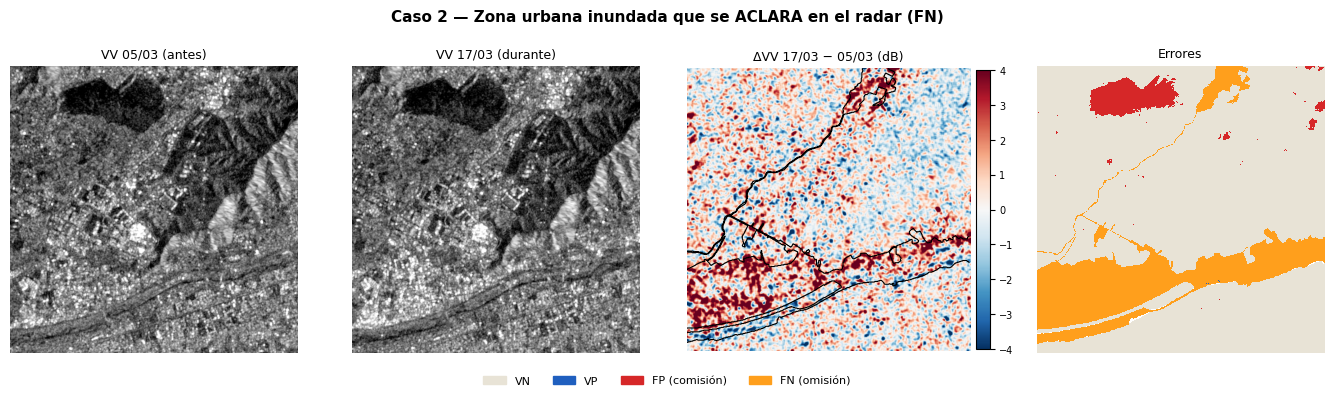

In [6]:
ID = 'Lima_0506'
d = analizar(conjunto_lima, ID)
T = transformacion_de(DIR_S1_LIMA / f'{ID}_S1Hand.tif')
s1_antes = s1_en_fecha(ee, ID_0503, T)

def suavizar(banda):
    banda = np.where(np.isfinite(banda), banda, np.nanmedian(banda))
    return uniform_filter(banda, size=5)

delta_vv = suavizar(d['s1'][0]) - suavizar(s1_antes[0])
inundado, seco = d['etiqueta'] == 1, d['etiqueta'] == 0
print(f"ΔVV mediana — inundado: {np.median(delta_vv[inundado]):+.2f} dB | no inundado: {np.median(delta_vv[seco]):+.2f} dB")
print(f"FN: {d['fn'].sum():,} de {inundado.sum():,} píxeles inundados ({100 * d['fn'].sum() / max(inundado.sum(), 1):.1f}% de omisión)")
resumen_casos.append({'caso': '2. Doble rebote / suelo saturado (urbano)', 'chip': ID, 'error': 'FN',
                      'evidencia': f"ΔVV(17/03−05/03) inundado {np.median(delta_vv[inundado]):+.2f} dB vs no inundado {np.median(delta_vv[seco]):+.2f} dB"})
figura_caso('Caso 2 — Zona urbana inundada que se ACLARA en el radar (FN)', [
    ('sar', s1_antes[0], 'VV 05/03 (antes)', {'vmin': -20, 'vmax': 5}),
    ('sar', d['s1'][0], 'VV 17/03 (durante)', {'vmin': -20, 'vmax': 5}),
    ('divergente', delta_vv, 'ΔVV 17/03 − 05/03 (dB)', {'vmin': -4, 'vmax': 4, 'contorno': inundado, 'color_contorno': 'black'}),
    ('errores', d['errores'], 'Errores', {}),
], DIR_FIGURAS / 'f9_caso2_urbano.png');

## Caso 3 — Vegetación inundada / agua somera no especular (FN) · Pakistán (test) y Bolivia
**Física:** si hay tallos o cultivos emergiendo del agua, o agua muy somera y rizada, el pulso no se refleja de forma especular: hay dispersión de volumen o doble rebote agua–tallo → **no se ve oscuro**. En el óptico, en cambio, el agua sí es evidente (la etiqueta se trazó sobre Sentinel-2).
**Prueba:** VH mediano de los píxeles de agua **perdidos** (FN) vs. los **acertados** (VP) y vs. lo no-agua.

Pakistan_849790: VH mediano — FN -18.1 dB | VP -24.9 dB | no agua -16.3 dB | omisión 84%
Bolivia_314919: VH mediano — FN -22.0 dB | VP -25.4 dB | no agua -15.0 dB | omisión 35%


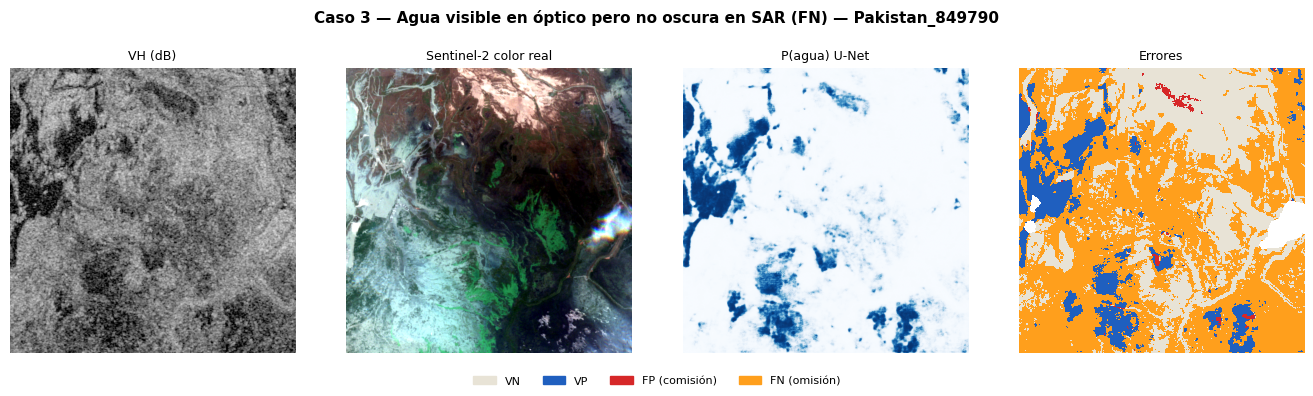

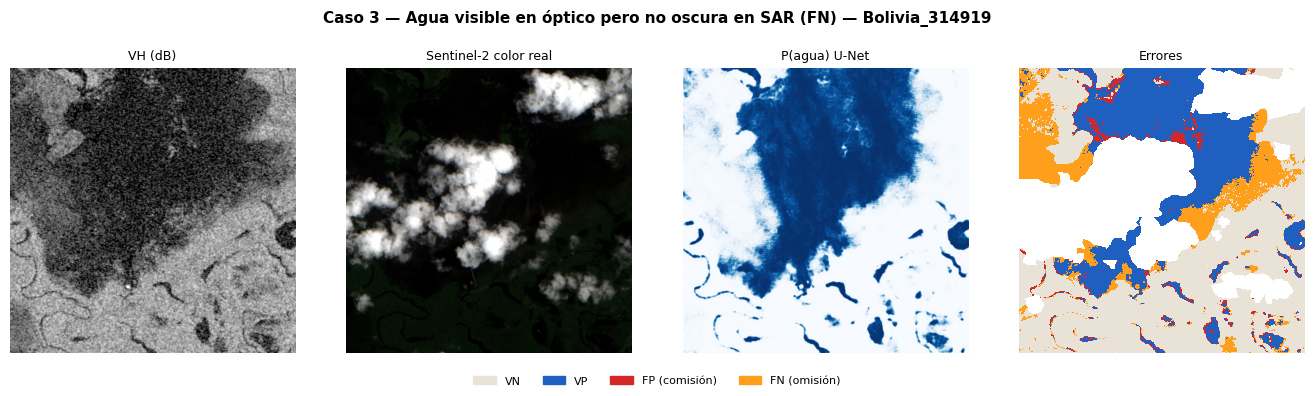

In [7]:
conjunto_sf = ConjuntoInundaciones(['Pakistan_849790', 'Bolivia_314919'], normalizador, en_memoria=False)
descargar_s2_sen1floods11(conjunto_sf.ids_chips)
for ID in conjunto_sf.ids_chips:
    d = analizar(conjunto_sf, ID)
    vh = d['s1'][1]
    med = lambda m: np.nanmedian(vh[m]) if m.any() else np.nan
    print(f"{ID}: VH mediano — FN {med(d['fn']):.1f} dB | VP {med(d['vp']):.1f} dB | no agua {med(d['etiqueta'] == 0):.1f} dB | omisión {100 * d['fn'].sum() / max((d['etiqueta'] == 1).sum(), 1):.0f}%")
    resumen_casos.append({'caso': '3. Vegetación inundada / agua no especular', 'chip': ID, 'error': 'FN',
                          'evidencia': f"VH mediano FN {med(d['fn']):.1f} dB vs VP {med(d['vp']):.1f} dB (no agua {med(d['etiqueta'] == 0):.1f})"})
    figura_caso(f'Caso 3 — Agua visible en óptico pero no oscura en SAR (FN) — {ID}', [
        ('sar', vh, 'VH (dB)', {'vmin': -30, 'vmax': -5}),
        ('rgb', leer_s2_rgb(ID), 'Sentinel-2 color real', {}),
        ('prob', d['prob'], 'P(agua) U-Net', {}),
        ('errores', d['errores'], 'Errores', {}),
    ], DIR_FIGURAS / f'f9_caso3_{ID}.png')

## Caso 4 — Superficies secas y lisas en zonas áridas (FP) · Somalia / Pakistán
**Física:** arena, suelo desnudo seco o superficies muy lisas reflejan el pulso lejos del sensor casi como el agua → oscuros en VV/VH. Es la causa de la **comisión** alta de Otsu en estos eventos (fase 1).
**Selección automática:** entre los chips de valid y test de Somalia y Pakistán, el que tiene más falsos positivos con el modelo final.

Chip con más FP: Pakistan_70625 | FP: 42844
VH mediano — FP -24.9 dB | no agua correcto -17.7 dB | agua real -23.4 dB


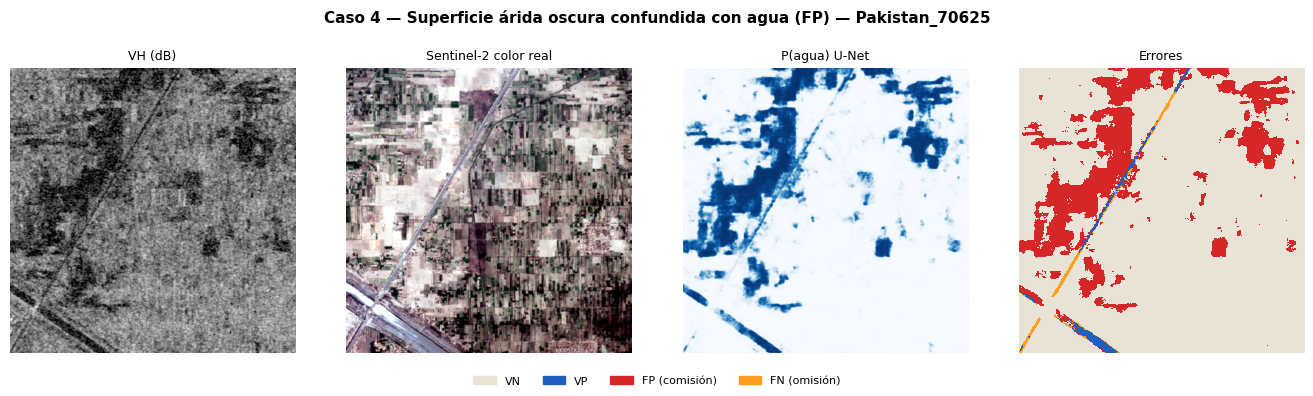

In [8]:
candidatos = pd.concat([leer_particion('valid'), leer_particion('test')])
candidatos = candidatos[candidatos['evento'].isin(['Somalia', 'Pakistan'])]['id_chip'].tolist()
conjunto_arido = ConjuntoInundaciones(candidatos, normalizador, en_memoria=False)
fp_por_chip = {ID: int(analizar(conjunto_arido, ID)['fp'].sum()) for ID in candidatos}
ID = max(fp_por_chip, key=fp_por_chip.get)
print('Chip con más FP:', ID, '| FP:', fp_por_chip[ID])
descargar_s2_sen1floods11([ID])
d = analizar(conjunto_arido, ID)
vh = d['s1'][1]
med = lambda m: np.nanmedian(vh[m]) if m.any() else np.nan
print(f"VH mediano — FP {med(d['fp']):.1f} dB | no agua correcto {med((d['prob'] <= 0.5) & (d['etiqueta'] == 0)):.1f} dB | agua real {med(d['etiqueta'] == 1):.1f} dB")
resumen_casos.append({'caso': '4. Superficie seca y lisa (árido)', 'chip': ID, 'error': 'FP',
                      'evidencia': f"VH mediano FP {med(d['fp']):.1f} dB vs no agua correcto {med((d['prob'] <= 0.5) & (d['etiqueta'] == 0)):.1f} dB"})
figura_caso(f'Caso 4 — Superficie árida oscura confundida con agua (FP) — {ID}', [
    ('sar', vh, 'VH (dB)', {'vmin': -30, 'vmax': -5}),
    ('rgb', leer_s2_rgb(ID), 'Sentinel-2 color real', {}),
    ('prob', d['prob'], 'P(agua) U-Net', {}),
    ('errores', d['errores'], 'Errores', {}),
], DIR_FIGURAS / 'f9_caso4_arido.png');

## Caso 5 — Agua permanente vs. inundación: diferencia de convención de etiquetado · Lima_0506
**Hipótesis:** el gran FP de Lima_0506 (Huachipa) es un **cuerpo de agua permanente**. Sen1Floods11 etiqueta **toda** el agua; EMS etiqueta **solo la inundación** → el modelo "acierta" físicamente pero cuenta como error.
**Prueba:** % de los FP con **ocurrencia de agua JRC > 50 %** (agua presente la mayor parte del tiempo entre 1984 y 2021) frente al % del chip con esa condición. Además, compuesto Sentinel-2 de 2017.

{'px_error': 8537, '%_errores_con_condicion': 0.0, '%_area_con_condicion': 0.1, 'razon_enriquecimiento': 0.0}


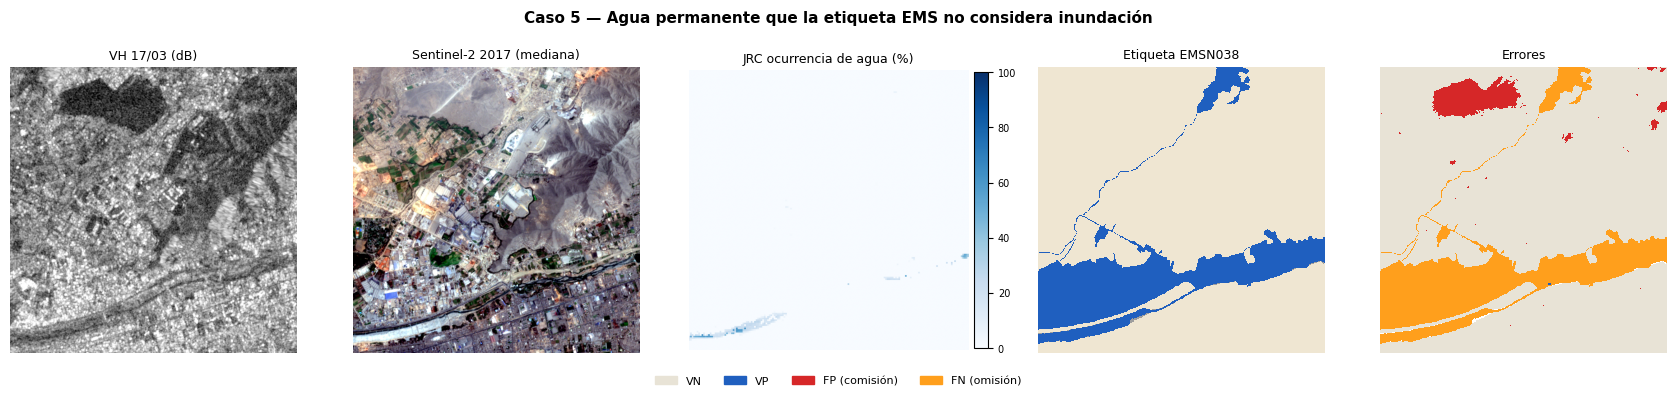

In [9]:
ID = 'Lima_0506'
d = analizar(conjunto_lima, ID)
T = transformacion_de(DIR_S1_LIMA / f'{ID}_S1Hand.tif')
ocurrencia = jrc_ocurrencia(ee, T)
rgb_2017 = s2_compuesto_rgb(ee, T)
e = enriquecimiento(d['fp'], ocurrencia > 50, d['validos'])
print(e)
resumen_casos.append({'caso': '5. Agua permanente (convención de etiqueta)', 'chip': ID, 'error': 'FP aparente',
                      'evidencia': f"{e['%_errores_con_condicion']}% de los FP con ocurrencia JRC>50% vs {e['%_area_con_condicion']}% del área (×{e['razon_enriquecimiento']})"})
figura_caso('Caso 5 — Agua permanente que la etiqueta EMS no considera inundación', [
    ('sar', d['s1'][1], 'VH 17/03 (dB)', {'vmin': -30, 'vmax': -5}),
    ('rgb', rgb_2017, 'Sentinel-2 2017 (mediana)', {}),
    ('continuo', ocurrencia, 'JRC ocurrencia de agua (%)', {'vmin': 0, 'vmax': 100, 'cmap': 'Blues'}),
    ('etiqueta', d['etiqueta'], 'Etiqueta EMSN038', {}),
    ('errores', d['errores'], 'Errores', {}),
], DIR_FIGURAS / 'f9_caso5_agua_permanente.png');

## Resumen de evidencias (va al informe)

In [10]:
tabla_casos = pd.DataFrame(resumen_casos)
tabla_casos.to_csv(DIR_RESULTADOS / 'f9_resumen_fallos.csv', index=False)
pd.set_option('display.max_colwidth', 200)
tabla_casos

,caso,chip,error,evidencia
0,1. Sombra / incidencia rasante,Lima_0104,FP,76.5% de los FP con θ_local>60° vs 23.0% del área (×3.33)
1,2. Doble rebote / suelo saturado (urbano),Lima_0506,FN,ΔVV(17/03−05/03) inundado +1.22 dB vs no inundado +0.03 dB
2,3. Vegetación inundada / agua no especular,Pakistan_849790,FN,VH mediano FN -18.1 dB vs VP -24.9 dB (no agua -16.3)
3,3. Vegetación inundada / agua no especular,Bolivia_314919,FN,VH mediano FN -22.0 dB vs VP -25.4 dB (no agua -15.0)
4,4. Superficie seca y lisa (árido),Pakistan_70625,FP,VH mediano FP -24.9 dB vs no agua correcto -17.7 dB
5,5. Agua permanente (convención de etiqueta),Lima_0506,FP aparente,0.0% de los FP con ocurrencia JRC>50% vs 0.1% del área (×0.0)


## Para traer a la conversación
Las salidas impresas y la figura de cada caso, y la tabla resumen. Con eso redactamos el entregable 5 y, después, decidimos si hacemos el **bono (fusión SAR + óptico)** antes del informe.